<a href="https://colab.research.google.com/github/Noorain-Malik/customer-segmentation-marketing-intelligence/blob/main/Training_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount("/content/drive")


Mounted at /content/drive


In [2]:
import pandas as pd

file_path = "/content/drive/MyDrive/customer_segmentation/Online Retail.xlsx"

df = pd.read_excel(file_path, sheet_name="Online Retail")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.info()
display(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [4]:
print("Exact duplicate rows:", df.duplicated().sum())

display(
    df[df.duplicated(keep=False)]
    .sort_values(["InvoiceNo", "StockCode"])
    .head(10)
)

Exact duplicate rows: 5268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [5]:
invoice_numbers = df["InvoiceNo"].astype(str).str.strip().str.upper()
is_cancellation = invoice_numbers.str.startswith("C")

print("Cancellation rows:", is_cancellation.sum())
print("Rows with negative quantity:", (df["Quantity"] < 0).sum())
print("Rows with zero quantity:", (df["Quantity"] == 0).sum())
print("Rows with zero or negative price:", (df["UnitPrice"] <= 0).sum())

display(df.loc[is_cancellation].head())

Cancellation rows: 9288
Rows with negative quantity: 10624
Rows with zero quantity: 0
Rows with zero or negative price: 2517


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [6]:
is_purchase = (
    df["CustomerID"].notna()
    & ~is_cancellation
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
)

purchases = df.loc[is_purchase].drop_duplicates().copy()

print("Original rows:", len(df))
print("Purchase rows kept:", len(purchases))
print("Unique customers kept:", purchases["CustomerID"].nunique())

purchases.head()

Original rows: 541909
Purchase rows kept: 392692
Unique customers kept: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
purchases["LineTotal"] = purchases["Quantity"] * purchases["UnitPrice"]

display(
    purchases[["InvoiceNo", "CustomerID", "Quantity", "UnitPrice", "LineTotal"]]
    .head()
)
display(
    purchases.nlargest(5, "LineTotal")[
        ["InvoiceNo", "CustomerID", "Description", "Quantity", "UnitPrice", "LineTotal"]
    ]
)

,InvoiceNo,CustomerID,Quantity,UnitPrice,LineTotal
0,536365,17850.0,6,2.55,15.30
1,536365,17850.0,6,3.39,20.34
2,536365,17850.0,8,2.75,22.00
3,536365,17850.0,6,3.39,20.34
4,536365,17850.0,6,3.39,20.34


,InvoiceNo,CustomerID,Description,Quantity,UnitPrice,LineTotal
540421,581483,16446.0,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60
61619,541431,12346.0,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60
222680,556444,15098.0,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00
173382,551697,16029.0,POSTAGE,1,8142.75,8142.75
348325,567423,17450.0,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72


In [8]:
match_columns = ["CustomerID", "StockCode", "UnitPrice", "Quantity"]

sale_lines = purchases[match_columns + ["InvoiceNo", "InvoiceDate"]].copy()
sale_lines["sale_row"] = sale_lines.index

cancel_lines = df.loc[
    is_cancellation & df["CustomerID"].notna() & (df["Quantity"] < 0),
    match_columns + ["InvoiceNo", "InvoiceDate"]
].copy()

cancel_lines["cancel_row"] = cancel_lines.index
cancel_lines["Quantity"] = -cancel_lines["Quantity"]

matches = sale_lines.merge(
    cancel_lines,
    on=match_columns,
    suffixes=("_sale", "_cancel")
)

matches = matches.loc[
    matches["InvoiceDate_cancel"] >= matches["InvoiceDate_sale"]
].copy()

unique_matches = matches.loc[
    ~matches["sale_row"].duplicated(keep=False)
    & ~matches["cancel_row"].duplicated(keep=False)
]

print("Purchase lines checked:", len(sale_lines))
print("Unique full-reversal candidates:", len(unique_matches))
display(unique_matches.head())

Purchase lines checked: 392692
Unique full-reversal candidates: 2139


,CustomerID,StockCode,UnitPrice,Quantity,InvoiceNo_sale,InvoiceDate_sale,sale_row,InvoiceNo_cancel,InvoiceDate_cancel,cancel_row
9,17850.0,82494L,2.55,12,536396,2010-12-01 10:51:00,290,C543611,2011-02-10 14:38:00,86895
15,16955.0,22680,1.25,20,536533,2010-12-01 13:31:00,1312,C538725,2010-12-14 11:16:00,29281
20,17841.0,84685,3.75,1,536557,2010-12-01 14:41:00,2083,C536979,2010-12-03 14:23:00,6782
24,12947.0,22635,9.95,2,536582,2010-12-01 16:21:00,2362,C539069,2010-12-15 16:57:00,32391
25,14606.0,21427,2.10,1,536591,2010-12-01 16:57:00,2421,C539244,2010-12-16 13:24:00,33254


In [9]:
reversed_sale_rows = unique_matches["sale_row"]
is_reversed = purchases.index.isin(reversed_sale_rows)

purchases_clean = purchases.loc[~is_reversed].copy()

print("Purchase lines excluded:", is_reversed.sum())
print("Purchase lines remaining:", len(purchases_clean))

Purchase lines excluded: 2139
Purchase lines remaining: 390553


In [10]:
# One calendar day after the last date in the original dataset
reference_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = purchases_clean.groupby("CustomerID", as_index=False).agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineTotal", "sum")
)

rfm["Recency"] = (reference_date - rfm["LastPurchase"].dt.normalize()).dt.days

rfm = rfm[["CustomerID", "Recency", "Frequency", "Monetary"]]

print("Reference date:", reference_date.date())
print("Customers:", len(rfm))
display(rfm.head())

Reference date: 2011-12-10
Customers: 4327


,CustomerID,Recency,Frequency,Monetary
0,12347.0,3,7,4310.00
1,12348.0,76,4,1797.24
2,12349.0,19,1,1757.55
3,12350.0,311,1,334.40
4,12352.0,37,8,2405.51


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.12,4.27,1968.76
std,100.17,7.68,8456.70
min,1.00,1.00,2.90
50%,51.00,2.00,660.21
90%,264.00,9.00,3584.23
95%,312.00,13.00,5751.66
99%,369.74,30.00,18362.65
max,374.00,208.00,280206.02


,Skewness
Recency,1.25
Frequency,12.04
Monetary,20.95


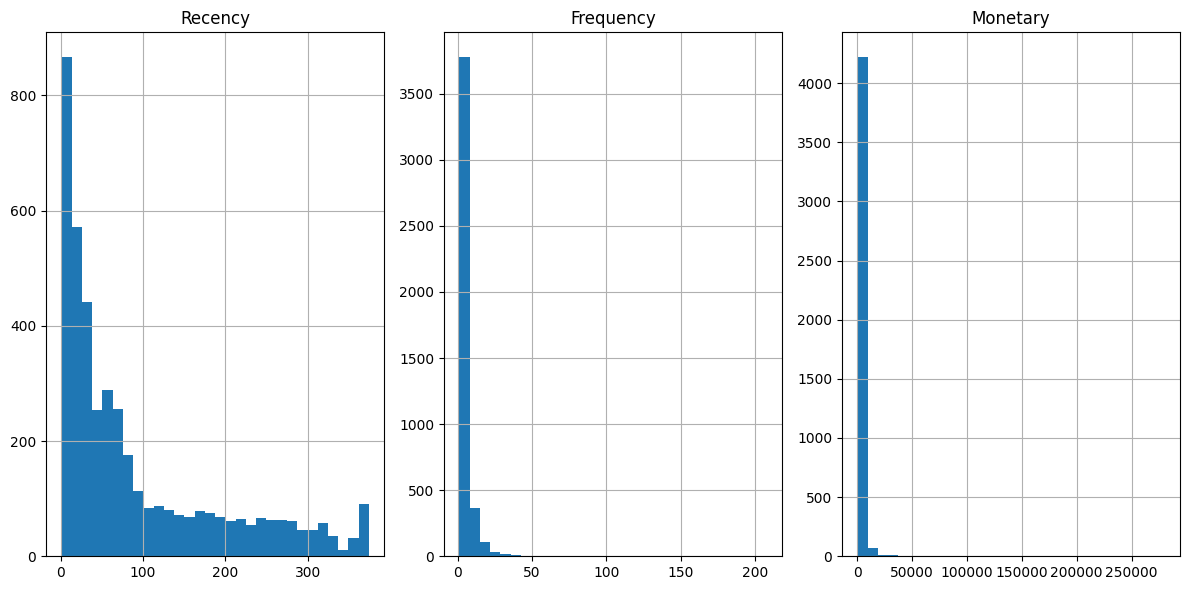

In [11]:
import matplotlib.pyplot as plt

rfm_columns = ["Recency", "Frequency", "Monetary"]

display(rfm[rfm_columns].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2))
display(rfm[rfm_columns].skew().round(2).rename("Skewness"))

rfm[rfm_columns].hist(bins=30, figsize=(12, 6), layout=(1, 3))
plt.tight_layout()
plt.show()

,Before,After log1p
Frequency,12.04,1.21
Monetary,20.95,0.36


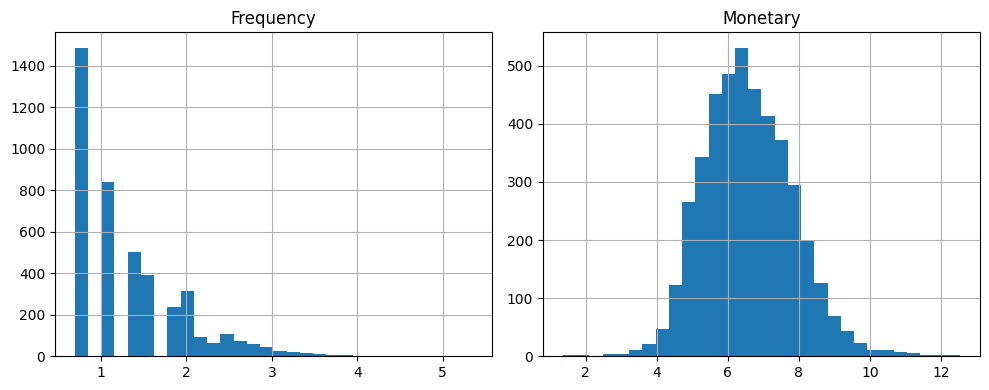

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rfm_model = rfm[["Recency", "Frequency", "Monetary"]].copy()
log_columns = ["Frequency", "Monetary"]

rfm_model[log_columns] = np.log1p(rfm_model[log_columns])

skew_comparison = pd.DataFrame({
    "Before": rfm[log_columns].skew(),
    "After log1p": rfm_model[log_columns].skew()
})

display(skew_comparison.round(2))

rfm_model[log_columns].hist(bins=30, figsize=(10, 4))
plt.tight_layout()
plt.savefig("rfm_after_log1p.svg", format="svg", bbox_inches="tight")
plt.show()

In [15]:
from sklearn.preprocessing import StandardScaler

rfm_columns = ["Recency", "Frequency", "Monetary"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_model[rfm_columns])

scaled_summary = pd.DataFrame({
    "Mean": X_scaled.mean(axis=0),
    "Standard deviation": X_scaled.std(axis=0)
}, index=rfm_columns)

print("Shape:", X_scaled.shape)
display(scaled_summary.round(3))

Shape: (4327, 3)


,Mean,Standard deviation
Recency,0.0,1.0
Frequency,0.0,1.0
Monetary,0.0,1.0


In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    results.append({
        "Clusters": k,
        "Inertia": model.inertia_,
        "Silhouette score": silhouette_score(X_scaled, labels)
    })

cluster_results = pd.DataFrame(results)
display(cluster_results.round(3))

,Clusters,Inertia,Silhouette score
0,2,6844.991,0.406
1,3,4271.087,0.416
2,4,3215.496,0.380
3,5,2736.103,0.344
4,6,2372.703,0.331
5,7,2143.634,0.301
6,8,1938.562,0.301


In [17]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

rfm_clustered = rfm.copy()
rfm_clustered["Cluster"] = kmeans.fit_predict(X_scaled)

cluster_profile = rfm_clustered.groupby("Cluster").agg(
    Customers=("CustomerID", "size"),
    Median_Recency_Days=("Recency", "median"),
    Median_Orders=("Frequency", "median"),
    Median_Spend_GBP=("Monetary", "median")
)

display(cluster_profile.round(2))

,Customers,Median_Recency_Days,Median_Orders,Median_Spend_GBP
Cluster,,,,
0,985,253.0,1.0,289.24
1,1320,18.0,7.0,2532.80
2,2022,46.0,2.0,506.12


In [18]:
segment_names = {
    0: "Inactive Low-Frequency Buyers",
    1: "Active High-Value Buyers",
    2: "Occasional Buyers"
}

rfm_clustered["Segment"] = rfm_clustered["Cluster"].map(segment_names)

display(
    rfm_clustered[
        ["CustomerID", "Recency", "Frequency", "Monetary", "Cluster", "Segment"]
    ].head()
)

,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12347.0,3,7,4310.00,1,Active High-Value Buyers
1,12348.0,76,4,1797.24,1,Active High-Value Buyers
2,12349.0,19,1,1757.55,2,Occasional Buyers
3,12350.0,311,1,334.40,0,Inactive Low-Frequency Buyers
4,12352.0,37,8,2405.51,1,Active High-Value Buyers


In [19]:
segment_summary = rfm_clustered.groupby("Segment").agg(
    Customers=("CustomerID", "size"),
    Total_Spend_GBP=("Monetary", "sum")
)

segment_summary["Customer_Share_Pct"] = (
    100 * segment_summary["Customers"] / segment_summary["Customers"].sum()
)

segment_summary["Spend_Share_Pct"] = (
    100 * segment_summary["Total_Spend_GBP"]
    / segment_summary["Total_Spend_GBP"].sum()
)

segment_summary = segment_summary.sort_values("Total_Spend_GBP", ascending=False)
display(segment_summary.round(2))

,Customers,Total_Spend_GBP,Customer_Share_Pct,Spend_Share_Pct
Segment,,,,
Active High-Value Buyers,1320,6905664.19,30.51,81.06
Occasional Buyers,2022,1224359.29,46.73,14.37
Inactive Low-Frequency Buyers,985,388800.52,22.76,4.56


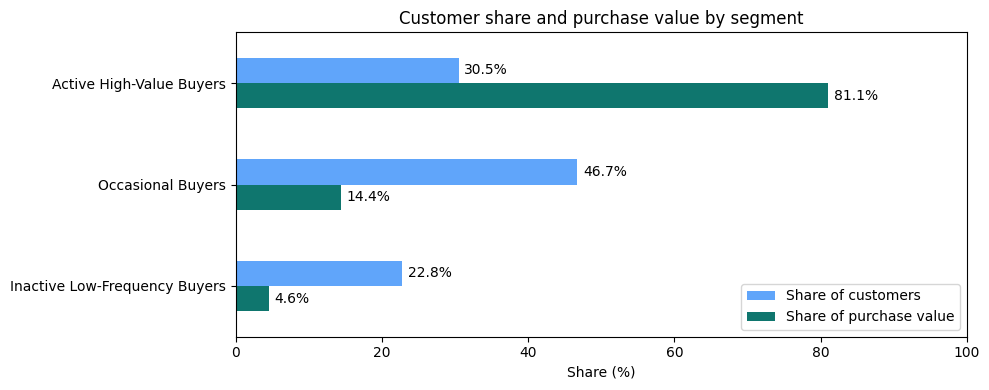

In [20]:
ax = segment_summary[
    ["Customer_Share_Pct", "Spend_Share_Pct"]
].rename(columns={
    "Customer_Share_Pct": "Share of customers",
    "Spend_Share_Pct": "Share of purchase value"
}).plot.barh(figsize=(10, 4), color=["#60A5FA", "#0F766E"])

ax.invert_yaxis()
ax.set_xlabel("Share (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.set_title("Customer share and purchase value by segment")

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=4)

plt.tight_layout()
plt.show()

In [22]:
from pathlib import Path

export_path = Path("/content/drive/MyDrive/customer_segmentation/customer_segments.csv")

dashboard_data = rfm_clustered[
    ["CustomerID", "Recency", "Frequency", "Monetary", "Cluster", "Segment"]
].copy()

dashboard_data["CustomerID"] = dashboard_data["CustomerID"].astype(int)
dashboard_data.to_csv(export_path, index=False)

# Read the saved file back to verify the export
saved_data = pd.read_csv(export_path)

print("Saved to", export_path)
print("Rows and columns:", saved_data.shape)
print("Unique customers:", saved_data["CustomerID"].nunique())
display(saved_data.head())

Saved to /content/drive/MyDrive/customer_segmentation/customer_segments.csv
Rows and columns: (4327, 6)
Unique customers: 4327


,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12347,3,7,4310.00,1,Active High-Value Buyers
1,12348,76,4,1797.24,1,Active High-Value Buyers
2,12349,19,1,1757.55,2,Occasional Buyers
3,12350,311,1,334.40,0,Inactive Low-Frequency Buyers
4,12352,37,8,2405.51,1,Active High-Value Buyers


In [23]:
import joblib

model_path = export_path.parent / "customer_segmentation_model.joblib"

joblib.dump({
    "scaler": scaler,
    "kmeans": kmeans,
    "rfm_columns": ["Recency", "Frequency", "Monetary"],
    "log_columns": ["Frequency", "Monetary"],
    "segment_names": segment_names
}, model_path)

print("Saved to:", model_path)

Saved to: /content/drive/MyDrive/customer_segmentation/customer_segmentation_model.joblib


In [1]:
import sklearn
print(f'python -m pip install "scikit-learn=={sklearn.__version__}" joblib numpy')

python -m pip install "scikit-learn==1.6.1" joblib numpy
